In [ ]:
import os
import csv
import math
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import networkx as nx
from matplotlib.patches import Patch

In [ ]:
students = []

subjects = [
    "Maths",
    "Physics",
    "Chemistry",
    "English",
    "Computer"
]

In [ ]:
def calculate_result(marks):
    total = sum(marks)
    percentage = total / len(marks)

    if percentage >= 90:
        grade = "A+"
    elif percentage >= 80:
        grade = "A"
    elif percentage >= 70:
        grade = "B"
    elif percentage >= 60:
        grade = "C"
    elif percentage >= 50:
        grade = "D"
    elif percentage >= 40:
        grade = "E"
    else:
        grade = "F"

    if all(mark >= 40 for mark in marks):
        result = "PASS"
    else:
        result = "FAIL"

    return total, percentage, grade, result

In [ ]:
def calculate_attendance(present_days, total_days):
    if total_days == 0:
        return 0

    percentage = (present_days / total_days) * 100
    return math.ceil(percentage)

In [ ]:
available_clubs = [
    "Coding",
    "Robotics",
    "Sports",
    "Music"
]

def check_club(club):
    return club in available_clubs

In [ ]:
club = input("Enter club name: ")

if check_club(club):
    print("Club is available.")
else:
    print("Club is not available.")

Enter club name: Coding
Club is available.


In [ ]:
def add_student():

    print("\n========== ADD STUDENT ==========")

    roll = int(input("Enter Roll Number: "))
    name = input("Enter Student Name: ")
    branch = input("Enter Branch: ")
    semester = int(input("Enter Semester: "))
    email = input("Enter Email: ")
    mobile = input("Enter Mobile Number: ")

    print("\n----- Enter Marks -----")

    marks = []

    for subject in subjects:
        mark = float(input(f"Enter {subject} marks: "))
        marks.append(mark)

    total, percentage, grade, result = calculate_result(marks)

    print("\n----- Attendance -----")

    total_days = int(input("Enter Total Working Days: "))
    present_days = int(input("Enter Present Days: "))

    attendance = calculate_attendance(
        present_days,
        total_days
    )

    print("\n----- Activities -----")

    club = input("Enter Club Name: ")
    hostel = input("Hostel Required? (Yes/No): ")

    student = {
        "Roll": roll,
        "Name": name,
        "Branch": branch,
        "Semester": semester,
        "Email": email,
        "Mobile": mobile,

        "Maths": marks[0],
        "Physics": marks[1],
        "Chemistry": marks[2],
        "English": marks[3],
        "Computer": marks[4],

        "Total": total,
        "Percentage": percentage,
        "Grade": grade,
        "Result": result,

        "Total_Days": total_days,
        "Present_Days": present_days,
        "Attendance": attendance,

        "Club": club,
        "Hostel": hostel
    }

    students.append(student)

    print("\nStudent added successfully!")

In [ ]:
def display_student(student):

    print("\n" + "=" * 50)
    print("              STUDENT DETAILS")
    print("=" * 50)

    print(f"Roll Number : {student['Roll']}")
    print(f"Name        : {student['Name']}")
    print(f"Branch      : {student['Branch']}")
    print(f"Semester    : {student['Semester']}")
    print(f"Email       : {student['Email']}")
    print(f"Mobile      : {student['Mobile']}")

    print("\n----- Academic Performance -----")

    for subject in subjects:
        print(f"{subject:<12}: {student[subject]}")

    print(f"\nTotal       : {student['Total']}")
    print(f"Percentage  : {student['Percentage']:.2f}%")
    print(f"Grade       : {student['Grade']}")
    print(f"Result      : {student['Result']}")

    print("\n----- Attendance -----")

    print(f"Total Days  : {student['Total_Days']}")
    print(f"Present     : {student['Present_Days']}")
    print(f"Attendance  : {student['Attendance']}%")

    print("\n----- Activities -----")

    print(f"Club        : {student['Club']}")
    print(f"Hostel      : {student['Hostel']}")

    print("=" * 50)

In [ ]:
def view_students():

    if len(students) == 0:
        print("\nNo students found.")
        return

    for student in students:
        display_student(student)

In [ ]:
def search_student():

    roll = int(input("Enter Roll Number to search: "))

    for student in students:

        if student["Roll"] == roll:
            display_student(student)
            return

    print("Student not found.")

In [ ]:
def update_student():

    roll = int(input("Enter Roll Number to update: "))

    for student in students:

        if student["Roll"] == roll:

            print("\nStudent found.")

            student["Name"] = input(
                "Enter new name: "
            )

            student["Branch"] = input(
                "Enter new branch: "
            )

            student["Semester"] = int(
                input("Enter new semester: ")
            )

            print("Student updated successfully.")
            return

    print("Student not found.")

In [ ]:
def delete_student():

    roll = int(input("Enter Roll Number to delete: "))

    for student in students:

        if student["Roll"] == roll:

            students.remove(student)

            print("Student deleted successfully.")
            return

    print("Student not found.")

In [ ]:
CSV_FILE = "student_management.csv"


def save_to_csv():

    if len(students) == 0:
        print("No student data available.")
        return

    df = pd.DataFrame(students)

    df.to_csv(
        CSV_FILE,
        index=False
    )

    print("\nData saved to CSV successfully.")

In [ ]:
def load_from_csv():

    global students

    if os.path.exists(CSV_FILE):

        df = pd.read_csv(CSV_FILE)

        students = df.to_dict(
            orient="records"
        )

        print("Student data loaded successfully.")

    else:
        print("CSV file does not exist.")

In [ ]:
def numpy_analysis():

    if len(students) == 0:
        print("No data available.")
        return

    marks = np.array([
        [
            s["Maths"],
            s["Physics"],
            s["Chemistry"],
            s["English"],
            s["Computer"]
        ]
        for s in students
    ])

    print("\n========== NUMPY ANALYSIS ==========")

    print("Marks Array:")
    print(marks)

    totals = np.sum(marks, axis=1)

    averages = np.mean(marks, axis=1)

    print("\nTotal Marks:")
    print(totals)

    print("\nAverage Marks:")
    print(np.round(averages, 2))

In [ ]:
def pandas_analysis():

    if not os.path.exists(CSV_FILE):
        print("First save student data to CSV.")
        return

    df = pd.read_csv(CSV_FILE)

    print("\n========== PANDAS ANALYSIS ==========")

    print("\nStudent Data:")
    print(df)

    print("\nSubject-wise Average:")

    print(
        df[subjects].mean()
    )

    print("\nHighest Marks:")

    print(
        df[subjects].max()
    )

    print("\nLowest Marks:")

    print(
        df[subjects].min()
    )

In [ ]:
def scipy_analysis():

    if len(students) == 0:
        print("No data available.")
        return

    percentages = np.array([
        s["Percentage"]
        for s in students
    ])

    print("\n========== SCIPY ANALYSIS ==========")

    print(
        "Mean:",
        np.mean(percentages)
    )

    print(
        "Median:",
        np.median(percentages)
    )

    print(
        "Standard Deviation:",
        np.std(percentages, ddof=1)
    )

    print(
        "Variance:",
        np.var(percentages, ddof=1)
    )

    print(
        "Skewness:",
        stats.skew(percentages)
    )

In [ ]:
def visualization():

    if not os.path.exists(CSV_FILE):
        print("First save student data to CSV.")
        return

    df = pd.read_csv(CSV_FILE)

    plt.figure(figsize=(10, 6))

    df[subjects].mean().plot(
        kind="bar"
    )

    plt.title("Average Marks by Subject")
    plt.xlabel("Subjects")
    plt.ylabel("Average Marks")

    plt.tight_layout()
    plt.show()

In [ ]:
def attendance_chart():

    if not os.path.exists(CSV_FILE):
        print("First save student data.")
        return

    df = pd.read_csv(CSV_FILE)

    plt.figure(figsize=(10, 6))

    plt.bar(
        df["Name"],
        df["Attendance"]
    )

    plt.title("Student Attendance")
    plt.xlabel("Student")
    plt.ylabel("Attendance %")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

# Graph Theory: Peer Mentoring Network (Directed Graph)
- Node = student
- Edge A → B = A strong in a subject where B is weak (same Branch + Semester)
- Weight = number of subjects A can help B with

In [ ]:
# thresholds
STRONG_MARK = 75   # mentor if marks >= this
WEAK_MARK = 50     # mentee if marks < this

def _norm(text):
    return str(text).strip().lower()

In [ ]:
def build_mentor_graph():
    G = nx.DiGraph()

    for s in students:
        G.add_node(
            s["Roll"],
            name=s["Name"],
            branch=s["Branch"],
            semester=s["Semester"]
        )

    for a in students:
        for b in students:

            if a["Roll"] == b["Roll"]:
                continue

            # same branch + semester only
            if _norm(a["Branch"]) != _norm(b["Branch"]):
                continue
            if a["Semester"] != b["Semester"]:
                continue

            # subjects where a strong and b weak
            helps = [
                sub for sub in subjects
                if a[sub] >= STRONG_MARK and b[sub] < WEAK_MARK
            ]

            if helps:
                G.add_edge(
                    a["Roll"], b["Roll"],
                    weight=len(helps),
                    subjects=helps,
                    gap=sum(a[sub] - b[sub] for sub in helps)
                )

    return G

In [ ]:
def mentor_analysis():

    if len(students) == 0:
        print("No data available.")
        return

    G = build_mentor_graph()

    print("\n========== MENTORING GRAPH ANALYSIS ==========")
    print(f"Students (nodes)       : {G.number_of_nodes()}")
    print(f"Mentor links (edges)   : {G.number_of_edges()}")
    print(f"Strong >= {STRONG_MARK}, Weak < {WEAK_MARK}")

    if G.number_of_edges() == 0:
        print("\nNo mentoring links found.")
        return

    name = lambda r: G.nodes[r]["name"]

    out_deg = dict(G.out_degree())
    in_deg = dict(G.in_degree())
    w_out = dict(G.out_degree(weight="weight"))
    out_c = nx.out_degree_centrality(G)
    in_c = nx.in_degree_centrality(G)
    btw = nx.betweenness_centrality(G)

    print("\n----- Student Roles -----")
    print(f"{'Roll':<8}{'Name':<14}{'Mentees':<9}{'Mentors':<9}{'OutC':<7}{'InC':<7}{'Betw':<7}Role")

    for r in G.nodes:
        if out_deg[r] and in_deg[r]:
            role = "Both"
        elif out_deg[r]:
            role = "Mentor"
        elif in_deg[r]:
            role = "Needs help"
        else:
            role = "Neutral"

        print(
            f"{r:<8}{name(r):<14}{out_deg[r]:<9}{in_deg[r]:<9}"
            f"{out_c[r]:<7.2f}{in_c[r]:<7.2f}{btw[r]:<7.2f}{role}"
        )

    print("\n----- Top Mentors (most students helped) -----")
    top = sorted(G.nodes, key=lambda r: (out_deg[r], w_out[r]), reverse=True)[:3]
    for r in top:
        if out_deg[r]:
            print(f"{name(r)} (Roll {r}): helps {out_deg[r]} students, {w_out[r]} subject-links")

    print("\n----- Students Needing Most Help -----")
    need = sorted(G.nodes, key=lambda r: in_deg[r], reverse=True)[:3]
    for r in need:
        if in_deg[r]:
            print(f"{name(r)} (Roll {r}): {in_deg[r]} possible mentors")

    print("\n----- Neutral Students (no links) -----")
    neutral = [name(r) for r in G.nodes if not out_deg[r] and not in_deg[r]]
    print(", ".join(neutral) if neutral else "None")

    # greedy assignment: least-loaded mentor, then biggest gap
    print("\n----- Suggested Mentor Assignment -----")
    load = {r: 0 for r in G.nodes}
    mentees = sorted(
        [r for r in G.nodes if in_deg[r]],
        key=lambda r: in_deg[r]          # fewest options first
    )

    for m in mentees:
        best = min(
            G.predecessors(m),
            key=lambda p: (load[p], -G[p][m]["gap"])
        )
        load[best] += 1
        subs = ", ".join(G[best][m]["subjects"])
        print(f"{name(m)} <- {name(best)}  [{subs}]")

    print("\n----- Mentor Load -----")
    for r, l in sorted(load.items(), key=lambda x: -x[1]):
        if l:
            print(f"{name(r)}: {l} mentee(s)")

In [ ]:
def mentor_graph_visualization():

    if len(students) == 0:
        print("No data available.")
        return

    G = build_mentor_graph()

    if G.number_of_edges() == 0:
        print("No mentoring links to draw.")
        return

    colors, sizes = [], []

    for r in G.nodes:
        o, i = G.out_degree(r), G.in_degree(r)

        if o and i:
            colors.append("orange")
        elif o:
            colors.append("green")
        elif i:
            colors.append("red")
        else:
            colors.append("lightgrey")

        sizes.append(600 + 300 * o)

    pos = nx.spring_layout(G, seed=42, k=1.2)

    plt.figure(figsize=(12, 8))

    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=sizes)
    nx.draw_networkx_labels(
        G, pos,
        labels={r: G.nodes[r]["name"] for r in G.nodes},
        font_size=9
    )
    nx.draw_networkx_edges(
        G, pos, arrows=True, arrowsize=18,
        width=[1 + 1.5 * G[u][v]["weight"] for u, v in G.edges],
        connectionstyle="arc3,rad=0.1",
        node_size=sizes
    )
    nx.draw_networkx_edge_labels(
        G, pos,
        edge_labels={
            (u, v): ",".join(x[:3] for x in G[u][v]["subjects"])
            for u, v in G.edges
        },
        font_size=7
    )

    plt.legend(handles=[
        Patch(color="green", label="Mentor"),
        Patch(color="red", label="Needs help"),
        Patch(color="orange", label="Both"),
        Patch(color="lightgrey", label="Neutral"),
    ])

    plt.title("Peer Mentoring Network (arrow: mentor -> mentee)")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

In [ ]:
def load_sample_data():
    # demo data: 2 groups (CSE sem 3, IT sem 3)
    sample = [
        (101, "Aryan", "CSE", 3, [92, 88, 45, 80, 90]),
        (102, "Riya",  "CSE", 3, [85, 40, 90, 78, 82]),
        (103, "Meera", "CSE", 3, [45, 48, 55, 60, 38]),
        (104, "Karan", "CSE", 3, [35, 42, 40, 70, 50]),
        (105, "Neha",  "CSE", 3, [65, 60, 62, 66, 64]),
        (106, "Dev",   "CSE", 3, [78, 52, 44, 85, 76]),
        (201, "Sara",  "IT",  3, [90, 85, 80, 88, 92]),
        (202, "Omar",  "IT",  3, [40, 70, 48, 55, 45]),
        (203, "Pooja", "IT",  3, [76, 44, 79, 52, 60]),
        (204, "Yash",  "IT",  3, [55, 58, 60, 62, 59]),
    ]

    existing = {s["Roll"] for s in students}
    added = 0

    for roll, name, branch, sem, marks in sample:

        if roll in existing:
            continue

        total, pct, grade, result = calculate_result(marks)
        present, days = 80, 100
        att = calculate_attendance(present, days)

        student = {
            "Roll": roll, "Name": name, "Branch": branch,
            "Semester": sem,
            "Email": f"{name.lower()}@example.com",
            "Mobile": "9000000000",
            "Maths": marks[0], "Physics": marks[1],
            "Chemistry": marks[2], "English": marks[3],
            "Computer": marks[4],
            "Total": total, "Percentage": pct,
            "Grade": grade, "Result": result,
            "Total_Days": days, "Present_Days": present,
            "Attendance": att,
            "Club": "Coding", "Hostel": "No"
        }
        students.append(student)
        added += 1

    print(f"{added} sample students added.")

In [ ]:
def main_menu():

    load_from_csv()

    while True:

        print("\n")
        print("=" * 55)
        print("        STUDENT MANAGEMENT SYSTEM")
        print("=" * 55)

        print("1. Add Student")
        print("2. View All Students")
        print("3. Search Student")
        print("4. Update Student")
        print("5. Delete Student")
        print("6. Save Data to CSV")
        print("7. NumPy Analysis")
        print("8. Pandas Analysis")
        print("9. SciPy Statistical Analysis")
        print("10. Student Performance Graph")
        print("11. Attendance Graph")
        print("12. Mentoring Graph Analysis")
        print("13. Mentoring Network Graph")
        print("14. Load Sample Data (demo)")
        print("0. Exit")

        choice = input("\nEnter your choice: ")

        if choice == "1":
            add_student()

        elif choice == "2":
            view_students()

        elif choice == "3":
            search_student()

        elif choice == "4":
            update_student()

        elif choice == "5":
            delete_student()

        elif choice == "6":
            save_to_csv()

        elif choice == "7":
            numpy_analysis()

        elif choice == "8":
            pandas_analysis()

        elif choice == "9":
            scipy_analysis()

        elif choice == "10":
            visualization()

        elif choice == "11":
            attendance_chart()

        elif choice == "12":
            mentor_analysis()

        elif choice == "13":
            mentor_graph_visualization()

        elif choice == "14":
            load_sample_data()

        elif choice == "0":

            save_to_csv()

            print("\nThank you for using Student Management System.")

            break

        else:
            print("\nInvalid choice. Try again.")

CSV file does not exist.


        STUDENT MANAGEMENT SYSTEM
1. Add Student
2. View All Students
3. Search Student
4. Update Student
5. Delete Student
6. Save Data to CSV
7. NumPy Analysis
8. Pandas Analysis
9. SciPy Statistical Analysis
10. Student Performance Graph
11. Attendance Graph
12. Mentoring Graph Analysis
13. Mentoring Network Graph
14. Load Sample Data (demo)
0. Exit

Enter your choice: 14
10 sample students added.


        STUDENT MANAGEMENT SYSTEM
1. Add Student
2. View All Students
3. Search Student
4. Update Student
5. Delete Student
6. Save Data to CSV
7. NumPy Analysis
8. Pandas Analysis
9. SciPy Statistical Analysis
10. Student Performance Graph
11. Attendance Graph
12. Mentoring Graph Analysis
13. Mentoring Network Graph
14. Load Sample Data (demo)
0. Exit

Enter your choice: 3
Enter Roll Number to search: 101

              STUDENT DETAILS
Roll Number : 101
Name        : Aryan
Branch      : CSE
Semester    : 3
Email       : aryan@example.com
Mobile      : 90000000

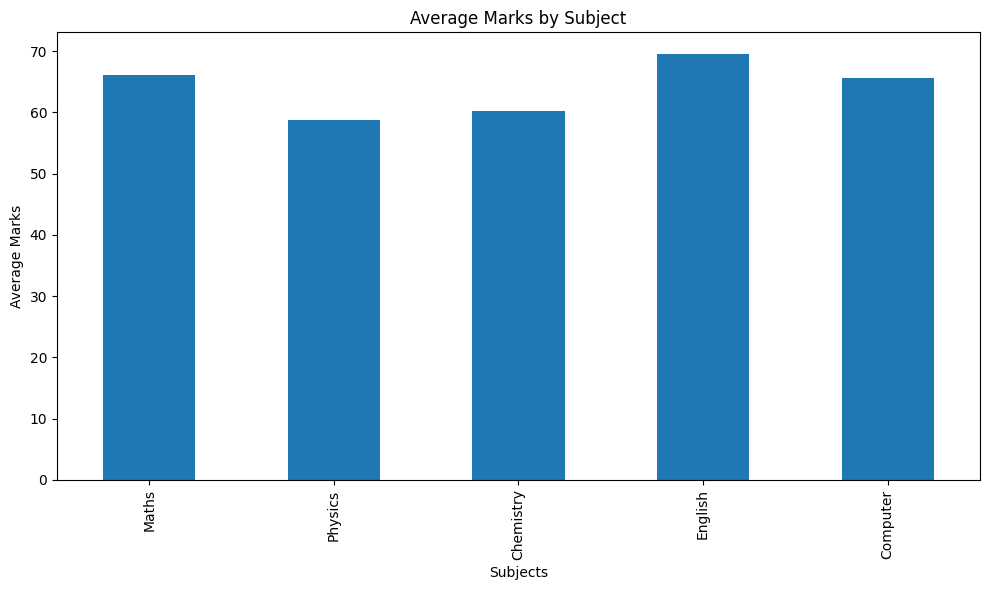



        STUDENT MANAGEMENT SYSTEM
1. Add Student
2. View All Students
3. Search Student
4. Update Student
5. Delete Student
6. Save Data to CSV
7. NumPy Analysis
8. Pandas Analysis
9. SciPy Statistical Analysis
10. Student Performance Graph
11. Attendance Graph
12. Mentoring Graph Analysis
13. Mentoring Network Graph
14. Load Sample Data (demo)
0. Exit

Enter your choice: 11


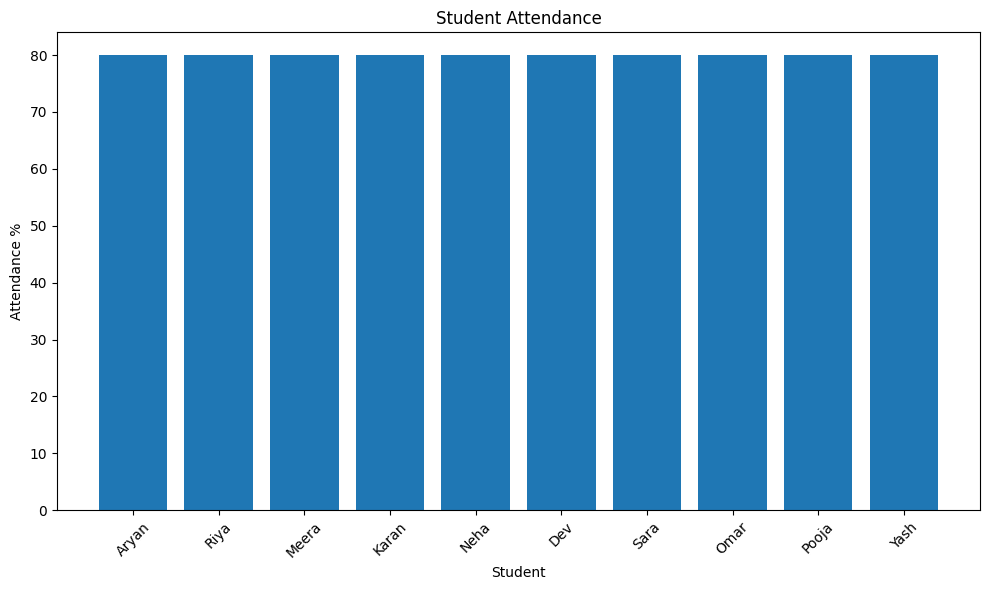



        STUDENT MANAGEMENT SYSTEM
1. Add Student
2. View All Students
3. Search Student
4. Update Student
5. Delete Student
6. Save Data to CSV
7. NumPy Analysis
8. Pandas Analysis
9. SciPy Statistical Analysis
10. Student Performance Graph
11. Attendance Graph
12. Mentoring Graph Analysis
13. Mentoring Network Graph
14. Load Sample Data (demo)
0. Exit

Enter your choice: 12

========== MENTORING GRAPH ANALYSIS ==========
Students (nodes)       : 10
Mentor links (edges)   : 12
Strong >= 75, Weak < 50

----- Student Roles -----
Roll    Name          Mentees  Mentors  OutC   InC    Betw   Role
101     Aryan         3        1        0.33   0.11   0.00   Both
102     Riya          4        1        0.44   0.11   0.01   Both
103     Meera         0        3        0.00   0.33   0.00   Needs help
104     Karan         0        3        0.00   0.33   0.00   Needs help
105     Neha          0        0        0.00   0.00   0.00   Neutral
106     Dev           2        1        0.22   0.11   

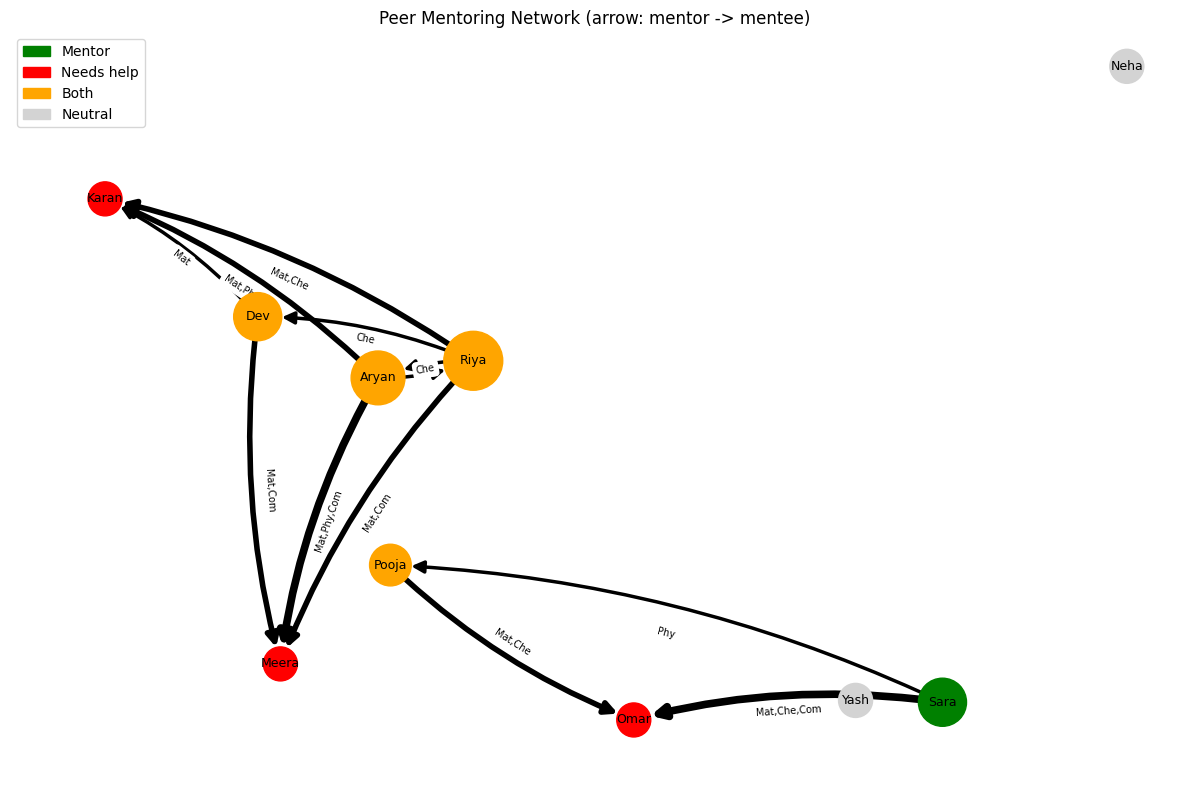



        STUDENT MANAGEMENT SYSTEM
1. Add Student
2. View All Students
3. Search Student
4. Update Student
5. Delete Student
6. Save Data to CSV
7. NumPy Analysis
8. Pandas Analysis
9. SciPy Statistical Analysis
10. Student Performance Graph
11. Attendance Graph
12. Mentoring Graph Analysis
13. Mentoring Network Graph
14. Load Sample Data (demo)
0. Exit

Enter your choice: 0

Data saved to CSV successfully.

Thank you for using Student Management System.


In [ ]:
main_menu()